# Nilgai YOLOv8 Nano - White-Hot Thermal Detection

**Dataset**: Synthetic white-hot thermal images  
**Model**: YOLOv8 Nano (`yolov8n.pt`)  

In [1]:
# Cell 1: Install Ultralytics
import sys
print('Python executable:', sys.executable)
!{sys.executable} -m pip install ultralytics --upgrade -q
print('Ultralytics installed/updated.')

Python executable: c:\CodeWorld\DL\venv\Scripts\python.exe
Ultralytics installed/updated.


In [2]:
# Cell 2: Verify GPU and Imports
import torch
from ultralytics import YOLO
import cv2
import numpy as np
import yaml
import shutil
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

print('PyTorch  :', torch.__version__)
print('CUDA     :', torch.version.cuda)
print('GPU avail:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name :', torch.cuda.get_device_name(0))
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM     : {total_vram:.1f} GB')

PyTorch  : 2.14.1+cu132
CUDA     : 13.2
GPU avail: True
GPU name : NVIDIA GeForce RTX 5050 Laptop GPU
VRAM     : 8.5 GB


In [3]:
# Cell 3: Diagnose Dataset - Images vs Labels
DS_ROOT = Path(r'yolo_ds_ta=27.0')
IMG_DIR = DS_ROOT / 'white_hot'   
LBL_DIR = DS_ROOT / 'labels'     

images = sorted(IMG_DIR.glob('*.png'))
labels = sorted(LBL_DIR.glob('*.txt'))
print(f'Images found : {len(images)}')
print(f'Labels found : {len(labels)}')
print()
print('Sample image name :', images[0].name)
print('Sample label name :', labels[0].name)
print()
print('Content of', labels[0].name, ':')
print(labels[0].read_text())

Images found : 100
Labels found : 100

Sample image name : white_hot_frame_0000.png
Sample label name : frame_0000.txt

Content of frame_0000.txt :
0 0.325000 0.526042 0.171875 0.152083



In [4]:
OUT_DS = DS_ROOT.parent / 'white_hot_yolo_ds_blender'

for split in ['train', 'val']:
    (OUT_DS / 'images' / split).mkdir(parents=True, exist_ok=True)
    (OUT_DS / 'labels' / split).mkdir(parents=True, exist_ok=True)

# Pair each image with its matching label
pairs = []
for img_path in images:
    frame_id = img_path.stem.replace('white_hot_', '')  # e.g. frame_0000
    lbl_path = LBL_DIR / (frame_id + '.txt')
    if lbl_path.exists():
        pairs.append((img_path, lbl_path))
    else:
        print('WARNING: No label for', img_path.name)

print(f'Matched pairs: {len(pairs)} / {len(images)}')

# Shuffle and split
random.seed(42)
random.shuffle(pairs)
split_idx   = int(0.8 * len(pairs))
train_pairs = pairs[:split_idx]
val_pairs   = pairs[split_idx:]
print(f'Train: {len(train_pairs)} | Val: {len(val_pairs)}')

def copy_pairs(pair_list, split):
    img_out = OUT_DS / 'images' / split
    lbl_out = OUT_DS / 'labels' / split
    for img_path, lbl_path in pair_list:
        new_stem = img_path.stem.replace('white_hot_', '')
        shutil.copy2(img_path, img_out / (new_stem + '.png'))
        shutil.copy2(lbl_path, lbl_out / lbl_path.name)

copy_pairs(train_pairs, 'train')
copy_pairs(val_pairs,   'val')

n_tr_img = len(list((OUT_DS / 'images' / 'train').iterdir()))
n_vl_img = len(list((OUT_DS / 'images' / 'val').iterdir()))
print()
print('Dataset ready at:', OUT_DS)
print('  images/train :', n_tr_img, 'files')
print('  images/val   :', n_vl_img, 'files')

Matched pairs: 100 / 100
Train: 80 | Val: 20

Dataset ready at: white_hot_yolo_ds_blender
  images/train : 80 files
  images/val   : 20 files


dataset.yaml

In [5]:
# Cell 5: Create dataset.yaml
YAML_PATH = OUT_DS / 'dataset.yaml'

dataset_cfg = {
    'path' : str(OUT_DS).replace('\\', '/'),
    'train': 'images/train',
    'val'  : 'images/val',
    'nc'   : 1,
    'names': {0: 'nilgai'},
}

with open(YAML_PATH, 'w') as f:
    yaml.dump(dataset_cfg, f, default_flow_style=False, sort_keys=False)

print('dataset.yaml written to:', YAML_PATH)
print()
print('--- Content ---')
print(YAML_PATH.read_text())

dataset.yaml written to: white_hot_yolo_ds_blender\dataset.yaml

--- Content ---
path: white_hot_yolo_ds_blender
train: images/train
val: images/val
nc: 1
names:
  0: nilgai



Pre-Training Sanity Check

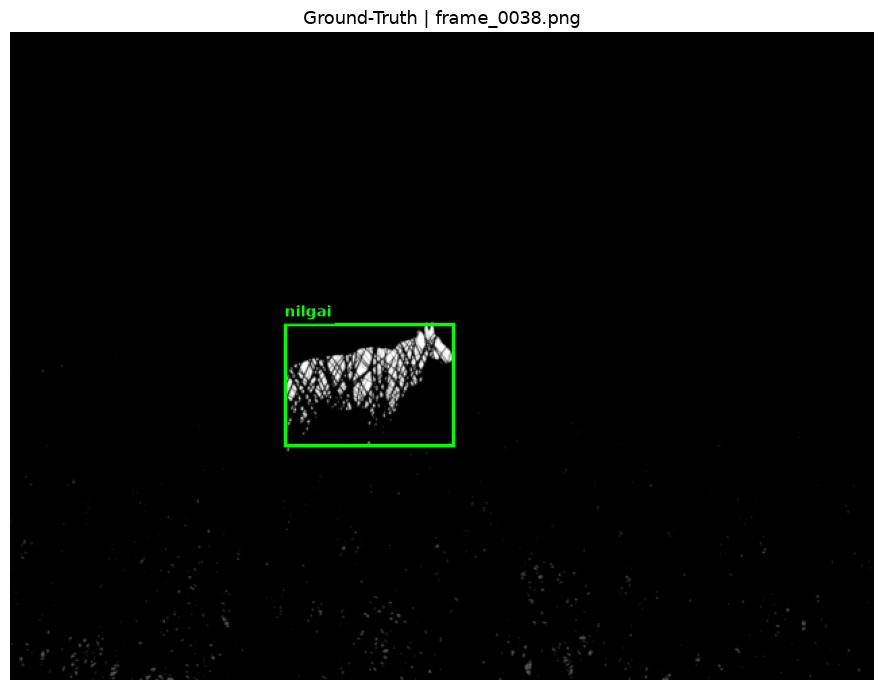

In [ ]:
CLASS_NAMES = ['nilgai']

def draw_yolo_boxes(img_path, lbl_path):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)
    with open(lbl_path) as f:
        for line in f.read().strip().splitlines():
            parts  = line.split()
            cls_id = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            x1 = (cx - bw / 2) * w
            y1 = (cy - bh / 2) * h
            rect = patches.Rectangle(
                (x1, y1), bw * w, bh * h,
                linewidth=2.5, edgecolor='lime', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(x1, y1 - 6, CLASS_NAMES[cls_id],
                    color='lime', fontsize=11, fontweight='bold',
                    bbox=dict(facecolor='black', alpha=0.5, pad=2))
    ax.set_title('Ground-Truth | ' + img_path.name, fontsize=13)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

sample_imgs = list((OUT_DS / 'images' / 'train').glob('*.png'))
sample_img  = random.choice(sample_imgs)
sample_lbl  = OUT_DS / 'labels' / 'train' / (sample_img.stem + '.txt')
draw_yolo_boxes(sample_img, sample_lbl)

Train YOLOv8 Nano

In [ ]:
model = YOLO('yolov8n.pt')  

results = model.train(
    data    = str(YAML_PATH),
    epochs  = 50,
    imgsz   = 640,
    device  = 0,        
    batch   = -1,       
    workers = 4,
    project = str(DS_ROOT.parent / 'runs'),
    name    = 'nilgai_white_hot_yolov8n',
    exist_ok= True,
    patience= 20,      
    plots   = True,
    verbose = True,
)

print('Training complete!')
BEST_WEIGHTS = Path(results.save_dir) / 'weights' / 'best.pt'
print('Best weights:', BEST_WEIGHTS)

Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=white_hot_yolo_ds_blender\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=nilgai_white_hot_yolov8n, n

Validate on Val Set

In [8]:
# Cell 8: Validate on Validation Set
best_model  = YOLO(str(BEST_WEIGHTS))
val_metrics = best_model.val(
    data   = str(YAML_PATH),
    device = 0,
    imgsz  = 640,
    split  = 'val',
)
print()
print('Validation Metrics:')
print(f'  mAP50    : {val_metrics.box.map50:.4f}')
print(f'  mAP50-95 : {val_metrics.box.map:.4f}')
print(f'  Precision: {val_metrics.box.mp:.4f}')
print(f'  Recall   : {val_metrics.box.mr:.4f}')

Ultralytics 8.4.182  Python-3.12.10 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 8151MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1402.8±162.2 MB/s, size: 105.6 KB)
val: Scanning C:\Projects\thermal_ir\white_hot_yolo_ds_blender\labels\val.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3s/it 2.7s8.5s
                   all         20         20      0.728       0.95       0.89      0.682
Speed: 1.7ms preprocess, 6.8ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\Projects\mscSem3\runs\detect\val-2

Validation Metrics:
  mAP50    : 0.8896
  mAP50-95 : 0.6821
  Precision: 0.7275
  Recall   : 0.9500


Inference on a Single Test Image

Running inference on: frame_0000.png


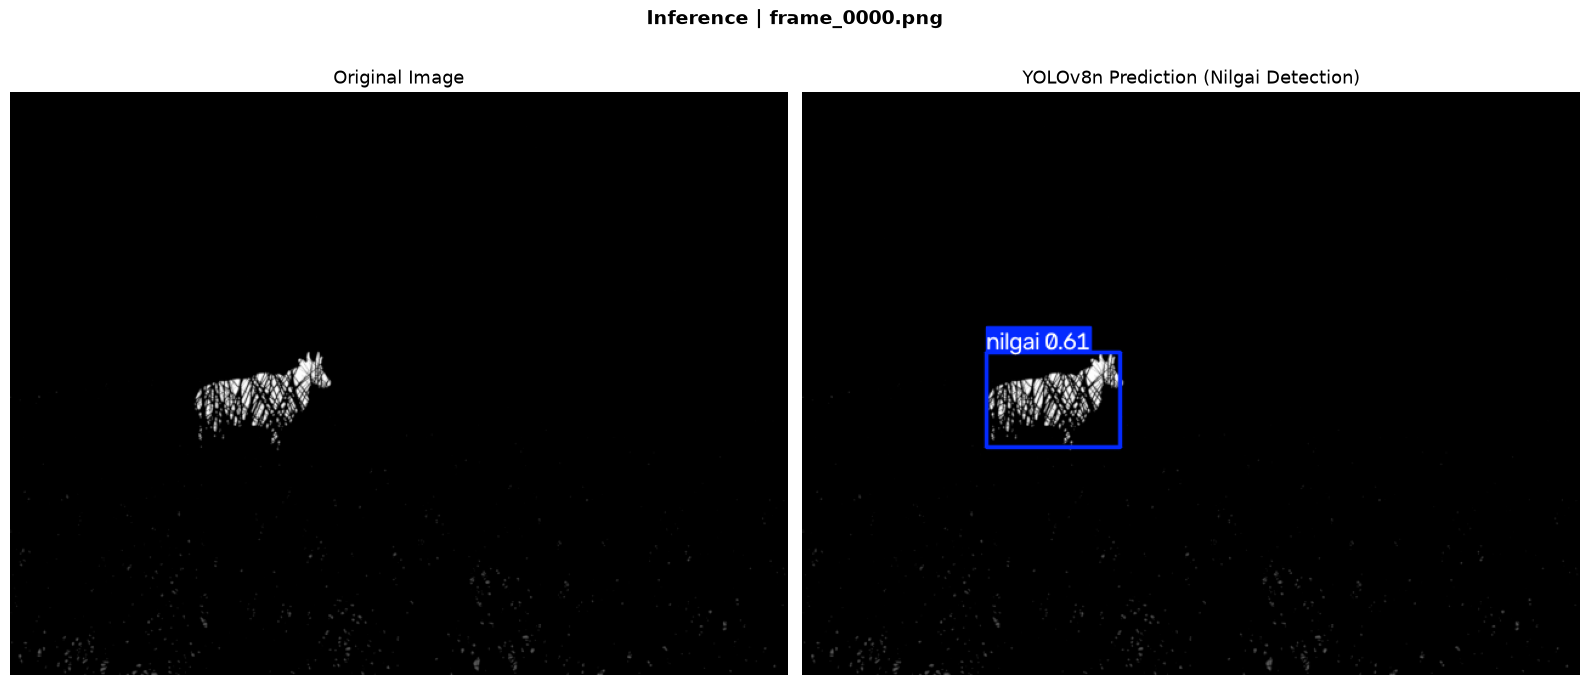

1 detection(s):
  [1] nilgai  conf=0.613  bbox=[151.3, 215.0, 261.7, 292.7]


In [ ]:
TEST_IMG = sample_imgs[0]  
print('Running inference on:', TEST_IMG.name)

preds = best_model.predict(
    source  = str(TEST_IMG),
    device  = 0,
    imgsz   = 640,
    conf    = 0.25,
    iou     = 0.45,
    save    = False,
    verbose = False,
)

result    = preds[0]
annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

orig = cv2.cvtColor(cv2.imread(str(TEST_IMG)), cv2.COLOR_BGR2RGB)
axes[0].imshow(orig)
axes[0].set_title('Original Image', fontsize=13)
axes[0].axis('off')

axes[1].imshow(annotated)
axes[1].set_title('YOLOv8n Prediction (Nilgai Detection)', fontsize=13)
axes[1].axis('off')

plt.suptitle('Inference | ' + TEST_IMG.name, fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

boxes = result.boxes
if len(boxes) == 0:
    print('No detections - try lowering conf threshold.')
else:
    print(f'{len(boxes)} detection(s):')
    for i, box in enumerate(boxes):
        cls  = int(box.cls[0])
        conf = float(box.conf[0])
        xyxy = [round(v, 1) for v in box.xyxy[0].tolist()]
        print(f'  [{i+1}] {CLASS_NAMES[cls]}  conf={conf:.3f}  bbox={xyxy}')

## Cell 10 — Display Training Curves

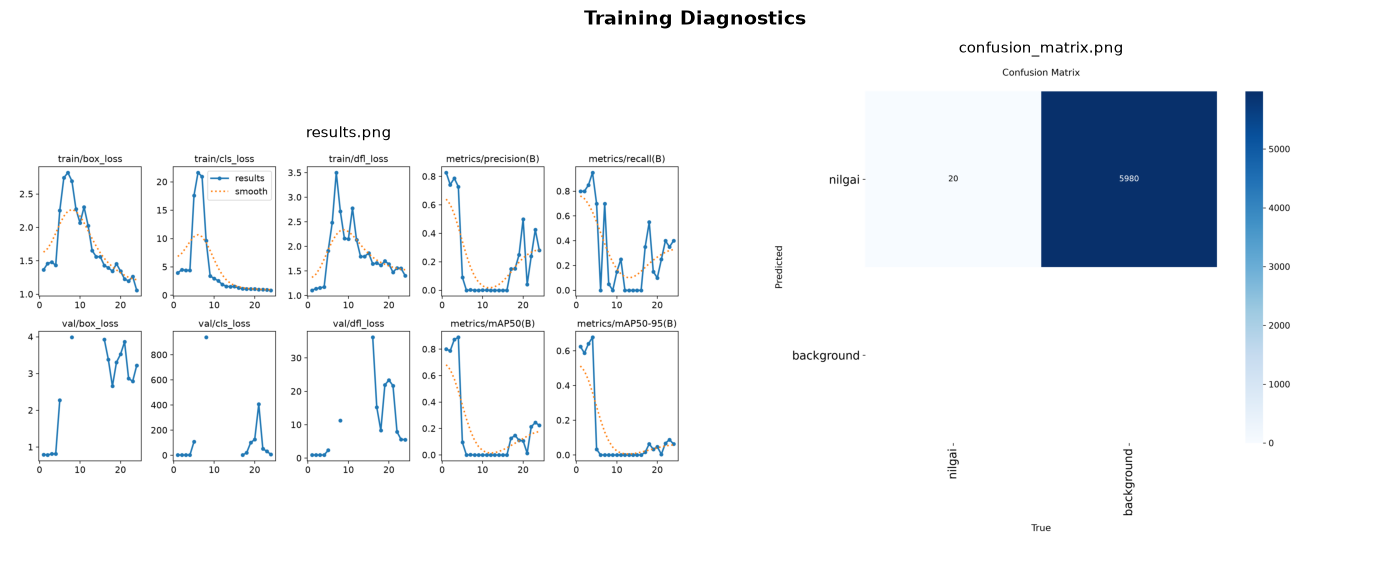

All outputs saved in: C:\Projects\mscSem3\runs\detect\runs\nilgai_white_hot_yolov8n


In [10]:
# Cell 10: Display Training Curves
SAVE_DIR   = Path(results.save_dir)
plot_files = ['results.png', 'confusion_matrix.png', 'PR_curve.png', 'F1_curve.png']
available  = [SAVE_DIR / p for p in plot_files if (SAVE_DIR / p).exists()]

if not available:
    print('No plots found. Save dir:', SAVE_DIR)
else:
    fig, axes = plt.subplots(1, len(available), figsize=(7 * len(available), 6))
    if len(available) == 1:
        axes = [axes]
    for ax, pf in zip(axes, available):
        ax.imshow(cv2.cvtColor(cv2.imread(str(pf)), cv2.COLOR_BGR2RGB))
        ax.set_title(pf.name, fontsize=11)
        ax.axis('off')
    plt.suptitle('Training Diagnostics', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

print('All outputs saved in:', SAVE_DIR)

## Cell 11 — Save All White-Hot Images with Ground-Truth Bounding Boxes

Draws GT boxes on **all 100** original `white_hot` images using OpenCV and saves them  
to `C:/Projects/mscSem3/Dataset/yolo_ds/white_hot_bounding_box/`.

Done! 100 images saved to: yolo_ds_ta=27.0\white_hot_bounding_box
Skipped (no label): 0


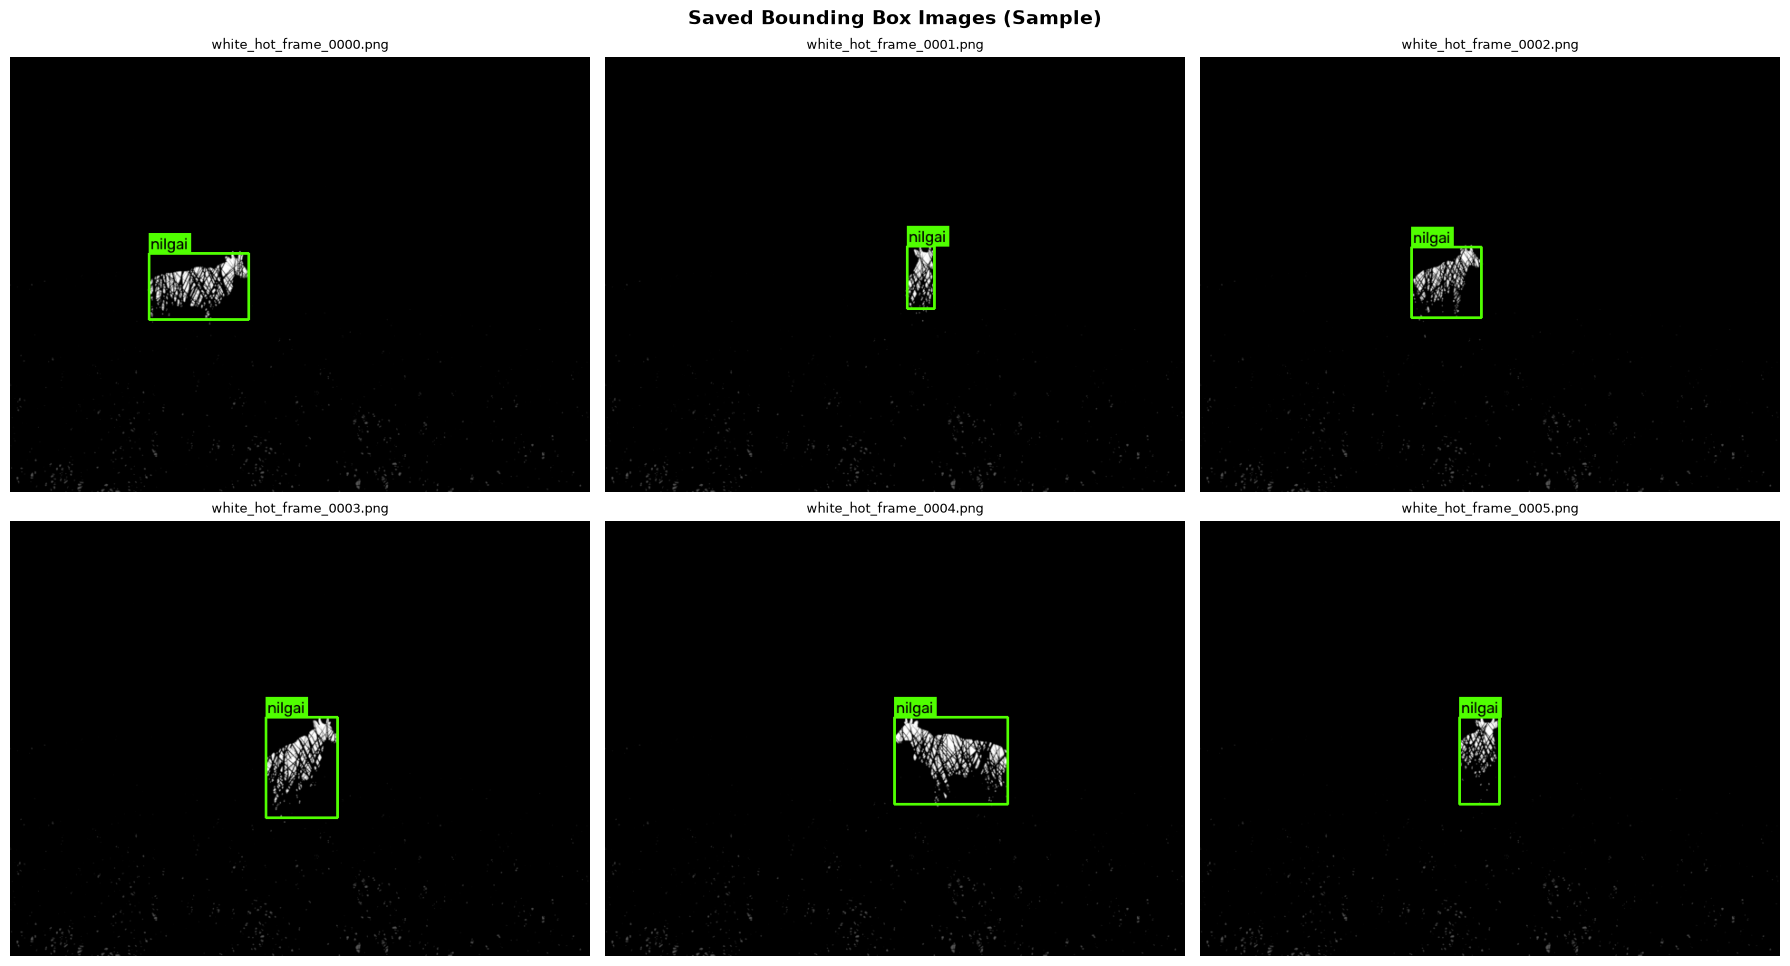

In [ ]:
BB_OUT = Path(r'yolo_ds_ta=27.0/white_hot_bounding_box')
BB_OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['nilgai']
BOX_COLOR   = (0, 255, 80)    # bright green (BGR)
TXT_COLOR   = (0, 255, 80)
THICKNESS   = 2
FONT        = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE  = 0.6

saved = 0
skipped = 0

all_imgs = sorted(Path(r'yolo_ds_ta=27.0/white_hot').glob('*.png'))

for img_path in all_imgs:
    frame_id = img_path.stem.replace('white_hot_', '')
    lbl_path = Path(r'yolo_ds_ta=27.0/labels') / (frame_id + '.txt')

    if not lbl_path.exists():
        print('SKIP (no label):', img_path.name)
        skipped += 1
        continue

    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    with open(lbl_path) as f:
        for line in f.read().strip().splitlines():
            parts  = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id      = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            x2 = int((cx + bw / 2) * w)
            y2 = int((cy + bh / 2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), BOX_COLOR, THICKNESS)
            label      = CLASS_NAMES[cls_id]
            (tw, th), _ = cv2.getTextSize(label, FONT, FONT_SCALE, 1)
            cv2.rectangle(img, (x1, y1 - th - 6), (x1 + tw + 4, y1), BOX_COLOR, -1)
            cv2.putText(img, label, (x1 + 2, y1 - 4), FONT, FONT_SCALE, (0, 0, 0), 1, cv2.LINE_AA)

    out_path = BB_OUT / img_path.name
    cv2.imwrite(str(out_path), img)
    saved += 1

print(f'Done! {saved} images saved to: {BB_OUT}')
print(f'Skipped (no label): {skipped}')

sample_files = sorted(BB_OUT.glob('*.png'))[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, fp in zip(axes, sample_files):
    ax.imshow(cv2.cvtColor(cv2.imread(str(fp)), cv2.COLOR_BGR2RGB))
    ax.set_title(fp.name, fontsize=9)
    ax.axis('off')
for ax in axes[len(sample_files):]:
    ax.axis('off')
plt.suptitle('Saved Bounding Box Images (Sample)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## colormap genrate

✅ Image successfully saved to: C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot_frame_0000_with_colorbar.png


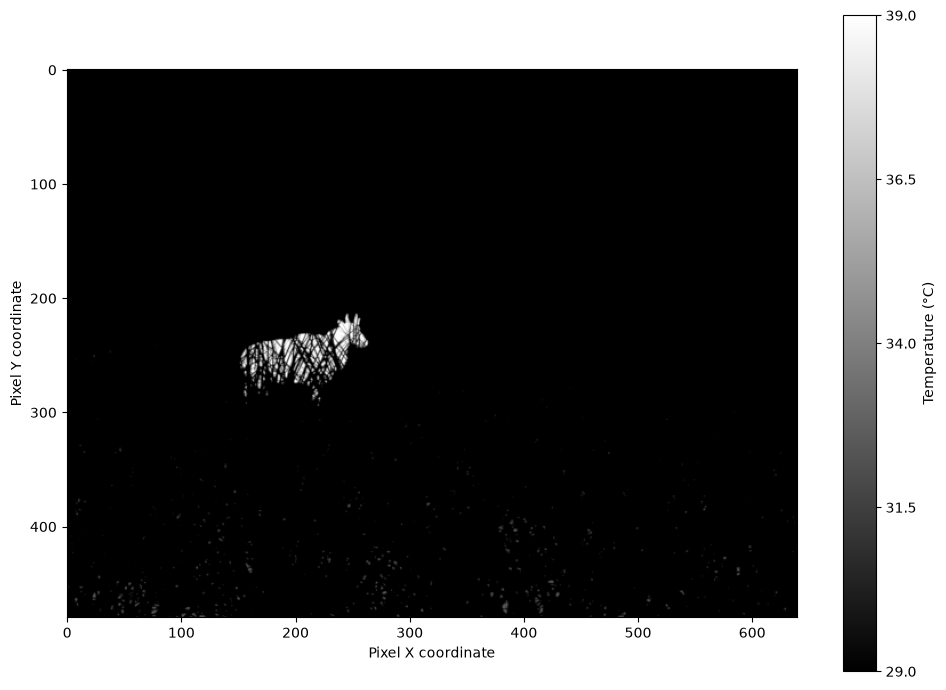

In [12]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Define your temperature variables
TA = 27.0  
TEMP_MAMMAL = TA + 12.0  # 39.0
TEMP_SOIL = TA + 3.0     # 30.0
TEMP_GRASS = TA + 2.0    # 29.0

# Calculate the window bounds for the colorbar
lo = min(TEMP_MAMMAL, TEMP_SOIL, TEMP_GRASS) # Bottom of colorbar (29.0)
hi = max(TEMP_MAMMAL, TEMP_SOIL, TEMP_GRASS) # Top of colorbar (39.0)

# 2. Load the exact image you specified
img_path = r"C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot\white_hot_frame_0000.png"
img = mpimg.imread(img_path)

# Ensure it is treated as a single-channel grayscale image
if len(img.shape) == 3:
    img_gray = img[:, :, 0]
else:
    img_gray = img

# 3. Create the plot
fig, ax = plt.subplots(figsize=(10, 7))

# Draw the image mapping pixel value 0.0 to 'lo' and 1.0 to 'hi'
cax = ax.imshow(img_gray, cmap='gray', vmin=0, vmax=1)

# Add and format the colorbar
cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Temperature (°C)')

# Distribute the temperature ticks evenly across the bar
cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
cbar.set_ticklabels([
    f"{lo:.1f}", 
    f"{lo + (hi-lo)*0.25:.1f}", 
    f"{lo + (hi-lo)*0.5:.1f}", 
    f"{lo + (hi-lo)*0.75:.1f}", 
    f"{hi:.1f}"
])

ax.set_xlabel('Pixel X coordinate')
ax.set_ylabel('Pixel Y coordinate')

plt.tight_layout()

# 4. Save the figure to your folder BEFORE showing it
save_path = r"C:\Projects\mscSem3\Dataset\yolo_ds_ta=27.0\white_hot_frame_0000_with_colorbar.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')

print(f"✅ Image successfully saved to: {save_path}")

# Display it in the notebook
plt.show()